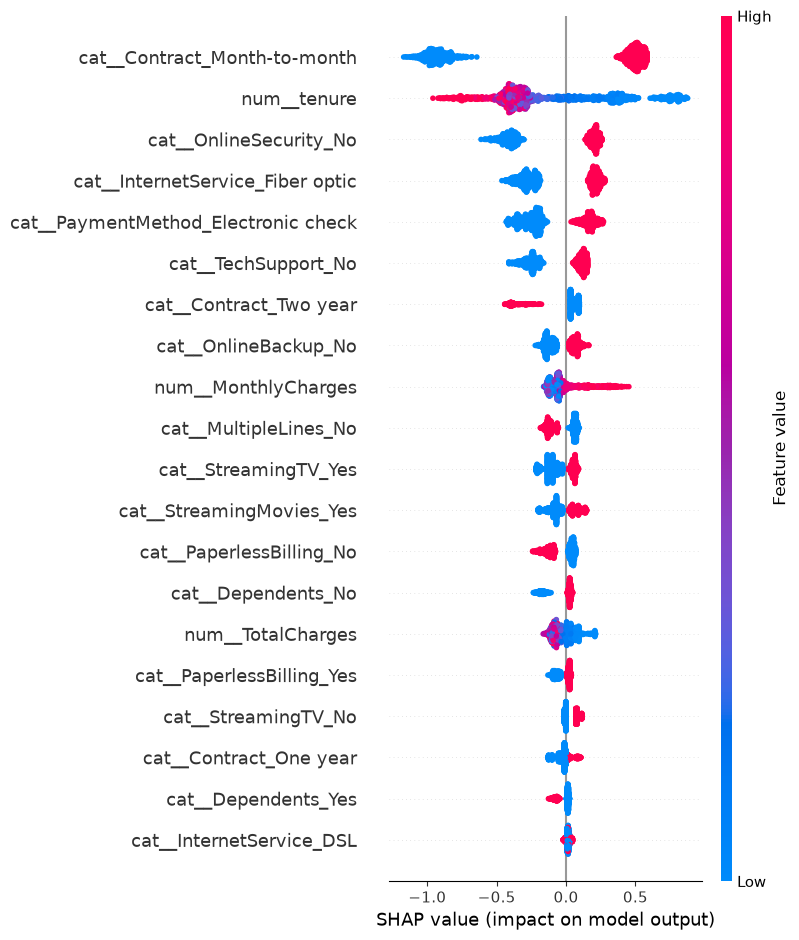

['../models/churn.pkl']

In [6]:
import shap, joblib, os
os.makedirs("../models", exist_ok=True)
Xt = best.named_steps["prep"].transform(X_te)
Xt = Xt.toarray() if hasattr(Xt,"toarray") else Xt
names = best.named_steps["prep"].get_feature_names_out()
sv = shap.TreeExplainer(best.named_steps["model"]).shap_values(Xt)
shap.summary_plot(sv, Xt, feature_names=names)
joblib.dump({"model":best,"threshold":th}, "../models/churn.pkl")

threshold: 0.5
              precision    recall  f1-score   support

           0       0.89      0.77      0.83      1033
           1       0.54      0.74      0.63       374

    accuracy                           0.77      1407
   macro avg       0.72      0.76      0.73      1407
weighted avg       0.80      0.77      0.78      1407



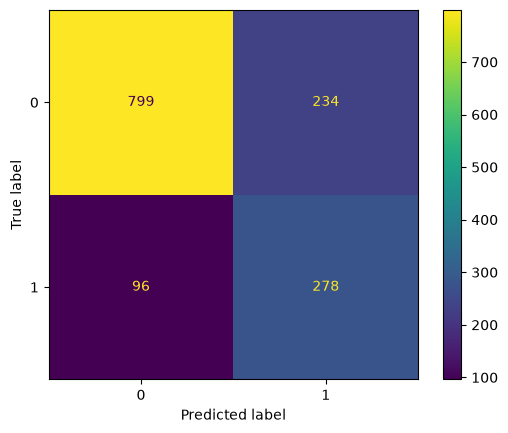

In [5]:
import numpy as np
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import classification_report, f1_score, ConfusionMatrixDisplay

best = Pipeline([("prep",prep),("smote",SMOTE(random_state=42)),
                 ("model",XGBClassifier(**study.best_params,eval_metric="logloss",random_state=42))])
proba_cv = cross_val_predict(best, X_tr, y_tr, cv=cv, method="predict_proba")[:,1]
ths = np.arange(0.2,0.8,0.02)
th = ths[np.argmax([f1_score(y_tr, proba_cv>=t) for t in ths])]
best.fit(X_tr, y_tr)
pred = best.predict_proba(X_te)[:,1] >= th
print("threshold:", round(th,2)); print(classification_report(y_te, pred))
ConfusionMatrixDisplay.from_predictions(y_te, pred)

In [4]:
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(t):
    p = dict(n_estimators=t.suggest_int("n_estimators",100,500),
             max_depth=t.suggest_int("max_depth",3,8),
             learning_rate=t.suggest_float("learning_rate",0.01,0.3,log=True),
             subsample=t.suggest_float("subsample",0.6,1.0),
             colsample_bytree=t.suggest_float("colsample_bytree",0.6,1.0))
    pipe = Pipeline([("prep",prep),("smote",SMOTE(random_state=42)),
                     ("model",XGBClassifier(**p,eval_metric="logloss",random_state=42))])
    return cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1").mean()

study = optuna.create_study(direction="maximize")
study.optimize(objective, n_trials=20)
print(study.best_value, study.best_params)

c:\customer churn\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


0.6374427541244607 {'n_estimators': 147, 'max_depth': 3, 'learning_rate': 0.03696281190680707, 'subsample': 0.8034489105897138, 'colsample_bytree': 0.807620500994485}


In [3]:
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.model_selection import cross_val_score, StratifiedKFold

models = {"LogReg": LogisticRegression(max_iter=1000),
          "RandomForest": RandomForestClassifier(n_estimators=200, random_state=42),
          "XGBoost": XGBClassifier(eval_metric="logloss", random_state=42)}
cv = StratifiedKFold(5, shuffle=True, random_state=42)
for name, m in models.items():
    pipe = Pipeline([("prep", prep), ("smote", SMOTE(random_state=42)), ("model", m)])
    print(name, cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="f1").mean().round(3))

LogReg 0.632
RandomForest 0.593
XGBoost 0.582


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
num = X.select_dtypes("number").columns
cat = X.select_dtypes("object").columns
prep = ColumnTransformer([("num", StandardScaler(), num),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])

C:\Users\Hp Omen 15\AppData\Local\Temp\ipykernel_19520\2976210756.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat = X.select_dtypes("object").columns


In [1]:
import pandas as pd
df = pd.read_csv("../data/churn.csv")
df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")
df = df.dropna().drop(columns="customerID")
df["Churn"] = (df["Churn"]=="Yes").astype(int)
X, y = df.drop(columns="Churn"), df["Churn"]
print(df.shape, y.mean())

(7032, 20) 0.26578498293515357
